# Attention-based multiple instance learning

As you recall, in the preivous notebook, we used a CNN to map each nodule slice $S_i$ to a 2048-dimension vector $h_i$. As you know, all of the vectors $h_1, h_2, ..., h_i$ form a whole nodule, which we will call $v$. $v$ can be defined the following way:

$v = \sum w_i \cdot h_i$

To make this reconstruction, we use **attention-based multiple instance learning**. In this apporach, each nodule is a bag, each slice an instance, and the model learns how much each slice should contribute to the bag-level representation.

In [26]:
import os, re, json, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

device: cpu


In [27]:
FEATURE_DIR = Path("dataset2d_features_slices")
LABELS_CSV  = Path("processed-data/annotations_all.csv")
CHECKPOINT_DIR = Path("mil_checkpoints")

FEAT_KEY    = "feature_vector"  # one 2048-dimension vector per slice NPZ

RADIMAGENET_CKPT = r"C:\Users\franc\.cache\huggingface\hub\models--Lab-Rasool--RadImageNet\snapshots\14460ee4c1276f6925611a63aa9a54a05d39eae0\ResNet50.pt"
IMG_SIZE = 224

N_FOLDS      = 5
HID_DIM      = 128
PROJ_DIM     = 512
DROPOUT      = 0.25
LR           = 1e-4
WEIGHT_DECAY = 1e-3
EPOCHS       = 100
PATIENCE     = 15
BATCH_SIZE   = 16
SEED         = 42

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)

In [28]:
df = pd.read_csv(LABELS_CSV)
if "patient_id" not in df.columns:
    df["patient_id"] = df["nodule_id"].astype(str).str.extract(r"(LIDC-IDRI-\d{4})")[0]
assert df["patient_id"].notna().all(), "could not parse patient ids - fix the regex or add a patient_id column"

# annotations_all.csv has one row per reader; MIL needs one label per nodule.
if not df["nodule_id"].astype(str).str.contains(r"_nodule\d+$").all():
    nodule_number = pd.to_numeric(df["nodule_id"], errors="raise").astype(int)
    df["nodule_id"] = df["patient_id"].astype(str) + "_nodule" + nodule_number.map("{:02d}".format)
df = (df.groupby(["patient_id", "nodule_id"], as_index=False, sort=False)
        .agg(malignancy=("malignancy", "mean")))
df["malignancy"] = np.floor(df["malignancy"] + 0.5).astype(int)

df["path"] = df["nodule_id"].map(lambda s: sorted(FEATURE_DIR.glob(f"{s}_slice*.npz")))
df = df[df["path"].map(bool)].reset_index(drop=True)
df["n_slices"] = df["path"].map(len)

# Scores 1-2 are benign; scores 3-5 are malignant.
classes = [0, 1]
cmap = {label: label for label in classes}
df["y"] = (df["malignancy"] >= 3).astype(int)
N_CLASSES = len(classes)

print(f"{len(df)} nodules, {df.patient_id.nunique()} patients, {N_CLASSES} classes")
print(df["y"].value_counts().sort_index().to_dict())
print(df["n_slices"].describe()[["min", "mean", "max"]].round(1).to_dict())

2279 nodules, 745 patients, 2 classes
{0: 746, 1: 1533}
{'min': 5.0, 'mean': 9.4, 'max': 49.0}


In [29]:
class NoduleBags(Dataset):
    def __init__(self, frame, train=False):
        self.df = frame.reset_index(drop=True)
        self.train = train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        vectors = []
        for path in row["path"]:
            with np.load(path, allow_pickle=False) as slice_data:
                feature = np.asarray(slice_data[FEAT_KEY], dtype=np.float32)
            if feature.shape != (2048,):
                raise ValueError(f"Expected a 2048-d feature vector in {path}, got {feature.shape}")
            vectors.append(feature)
        if not vectors:
            raise ValueError(f"No feature slices found for {row['nodule_id']}")
        bag = torch.from_numpy(np.stack(vectors))
        return bag, int(row["y"]), str(row["nodule_id"])


def collate(batch):
    bags, labels, ids = zip(*batch)
    max_slices = max(bag.shape[0] for bag in bags)
    feature_dim = bags[0].shape[1]
    X = torch.zeros((len(bags), max_slices, feature_dim), dtype=bags[0].dtype)
    mask = torch.zeros((len(bags), max_slices), dtype=torch.bool)
    for index, bag in enumerate(bags):
        n_slices = bag.shape[0]
        X[index, :n_slices] = bag
        mask[index, :n_slices] = True
    return X, mask, torch.tensor(labels, dtype=torch.long), list(ids)

In [30]:
class MILNet(nn.Module):
    def __init__(self, in_dim=2048, proj_dim=PROJ_DIM, hid_dim=HID_DIM, n_classes=2, dropout=DROPOUT, pooling="attention"):
        super().__init__()
        self.pooling = pooling
        self.proj = nn.Sequential(nn.LayerNorm(in_dim), nn.Linear(in_dim, proj_dim), nn.ReLU(), nn.Dropout(dropout)) # embed
        if pooling == "attention":
            self.V = nn.Linear(proj_dim, hid_dim); self.U = nn.Linear(proj_dim, hid_dim); self.w = nn.Linear(hid_dim, 1)
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(proj_dim, n_classes))

    def forward(self, x, mask):
        h = self.proj(x)                                                        # (B, K, D)
        if self.pooling == "attention":
            e = self.w(torch.tanh(self.V(h)) * torch.sigmoid(self.U(h))).squeeze(-1) # scoring each instance
            e = e.masked_fill(~mask, float("-inf"))
            a = torch.softmax(e, dim=1) # normalize                                      # (B, K), padding gets exactly 0
            v = torch.bmm(a.unsqueeze(1), h).squeeze(1)
        elif self.pooling == "mean":
            a = mask.float() / mask.sum(1, keepdim=True)
            v = torch.bmm(a.unsqueeze(1), h).squeeze(1) # pool
        elif self.pooling == "max":
            a = None
            v = h.masked_fill(~mask.unsqueeze(-1), float("-inf")).max(1).values
        return self.classifier(v), a # classify the bag


def save_attention_checkpoint(model, fold, checkpoint_dir=CHECKPOINT_DIR):
    if model.pooling != "attention":
        raise ValueError("Only attention-pooled models are saved by this helper")
    checkpoint_dir = Path(checkpoint_dir)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    path = checkpoint_dir / f"mil_attention_fold_{fold}.pt"
    torch.save({
        "model_state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
        "model_config": {
            "in_dim": 2048,
            "proj_dim": PROJ_DIM,
            "hid_dim": HID_DIM,
            "n_classes": N_CLASSES,
            "dropout": DROPOUT,
            "pooling": "attention",
        },
        "classes": [int(label) for label in classes],
        "label_to_index": {int(label): int(index) for label, index in cmap.items()},
        "fold": int(fold),
    }, path)
    return path

In [31]:
def metrics(y, prob):
    pred = prob.argmax(1)
    try:
        auc = roc_auc_score(y, prob[:, 1]) if N_CLASSES == 2 else roc_auc_score(y, prob, multi_class="ovr", average="macro")
    except ValueError:
        auc = float("nan")
    return dict(auc=auc, acc=accuracy_score(y, pred), f1=f1_score(y, pred, average="binary" if N_CLASSES == 2 else "macro"))

@torch.no_grad()
def predict(model, loader):
    model.eval(); P, Y, A, I = [], [], {}, []
    for X, M, y, ids in loader:
        logits, a = model(X.to(DEVICE), M.to(DEVICE))
        P.append(torch.softmax(logits, 1).cpu()); Y.append(y)
        if a is not None:
            for j, nid in enumerate(ids): A[nid] = a[j, M[j]].cpu().numpy()
        I += ids
    return torch.cat(P).numpy(), torch.cat(Y).numpy(), A, I

def fit(train_df, val_df, pooling):
    seed_all(SEED)
    tl = DataLoader(NoduleBags(train_df, train=True), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
    vl = DataLoader(NoduleBags(val_df), batch_size=BATCH_SIZE, collate_fn=collate)
    model = MILNet(n_classes=N_CLASSES, pooling=pooling).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    cnt = np.bincount(train_df["y"], minlength=N_CLASSES)
    crit = nn.CrossEntropyLoss(weight=torch.tensor(cnt.sum() / (N_CLASSES * np.maximum(cnt, 1)), dtype=torch.float, device=DEVICE))
    best, best_state, bad, hist = -1, None, 0, []
    for ep in range(EPOCHS):
        model.train(); tot = 0
        for X, M, y, _ in tl:
            opt.zero_grad()
            loss = crit(model(X.to(DEVICE), M.to(DEVICE))[0], y.to(DEVICE))
            loss.backward(); opt.step(); tot += loss.item() * len(y)
        p, yv, _, _ = predict(model, vl); m = metrics(yv, p)
        hist.append((tot / len(train_df), m["auc"]))
        score = m["auc"] if not np.isnan(m["auc"]) else m["acc"]
        if score > best: best, bad, best_state = score, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    return model, hist

In [32]:
POOLINGS = ["attention", "mean", "max"]
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
results, oof_prob, attn_store, histories = [], {p: np.zeros((len(df), N_CLASSES)) for p in POOLINGS}, {}, {}
attention_checkpoint_paths = []

for fold, (tr_idx, te_idx) in enumerate(sgkf.split(df, df["y"], df["patient_id"])):
    trv = df.iloc[tr_idx]
    gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
    a, b = next(gss.split(trv, groups=trv["patient_id"]))
    train_df, val_df, test_df = trv.iloc[a], trv.iloc[b], df.iloc[te_idx]
    assert not set(train_df.patient_id) & set(test_df.patient_id) and not set(val_df.patient_id) & set(test_df.patient_id)
    for pooling in POOLINGS:
        model, hist = fit(train_df, val_df, pooling)
        if pooling == "attention":
            attention_checkpoint_paths.append(save_attention_checkpoint(model, fold))
        p, y, A, ids = predict(model, DataLoader(NoduleBags(test_df), batch_size=BATCH_SIZE, collate_fn=collate))
        oof_prob[pooling][te_idx] = p
        results.append(dict(fold=fold, pooling=pooling, **metrics(y, p)))
        histories[(fold, pooling)] = hist
        if pooling == "attention":
            attn_store.update(A)
    print(
        f"fold {fold} done:",
        {r['pooling']: round(r['auc'], 3) for r in results if r['fold'] == fold},
        "attention checkpoint:", attention_checkpoint_paths[-1],
    )

res = pd.DataFrame(results)
summary = res.groupby("pooling")[["auc", "acc", "f1"]].agg(["mean", "std"]).round(3)
summary

fold 0 done: {'attention': 0.737, 'mean': 0.711, 'max': 0.732} attention checkpoint: mil_checkpoints\mil_attention_fold_0.pt
fold 1 done: {'attention': 0.689, 'mean': 0.687, 'max': 0.712} attention checkpoint: mil_checkpoints\mil_attention_fold_1.pt
fold 2 done: {'attention': 0.703, 'mean': 0.699, 'max': 0.722} attention checkpoint: mil_checkpoints\mil_attention_fold_2.pt
fold 3 done: {'attention': 0.688, 'mean': 0.658, 'max': 0.691} attention checkpoint: mil_checkpoints\mil_attention_fold_3.pt
fold 4 done: {'attention': 0.736, 'mean': 0.722, 'max': 0.739} attention checkpoint: mil_checkpoints\mil_attention_fold_4.pt


auc           acc            f1       
            mean    std   mean    std   mean    std
pooling                                            
attention  0.711  0.024  0.638  0.010  0.700  0.034
max        0.719  0.019  0.663  0.039  0.734  0.057
mean       0.695  0.025  0.602  0.046  0.641  0.081

,auc,acc,f1
pooling,,,
attention,0.693,0.638,0.702
mean,0.680,0.602,0.649
max,0.706,0.663,0.739


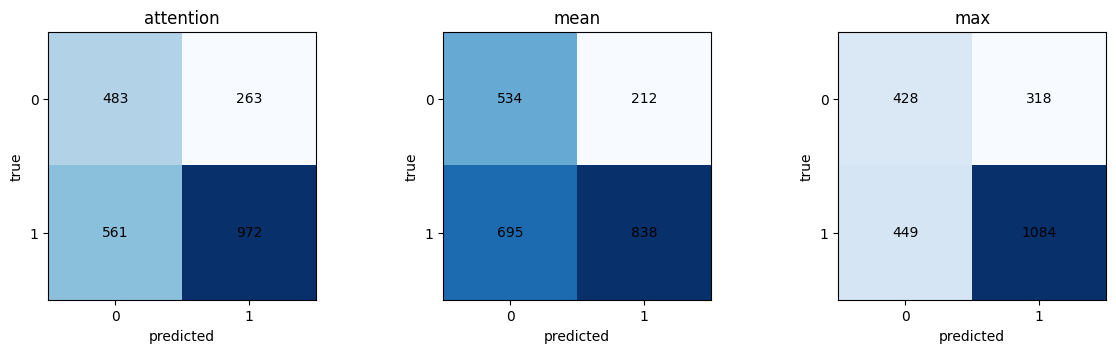

In [33]:
y_all = df["y"].values
rows = []
for p in POOLINGS:
    rows.append(dict(pooling=p, **metrics(y_all, oof_prob[p])))
display(pd.DataFrame(rows).round(3).set_index("pooling"))

fig, axs = plt.subplots(1, len(POOLINGS), figsize=(4 * len(POOLINGS), 3.6))
for ax, p in zip(axs, POOLINGS):
    cm = confusion_matrix(y_all, oof_prob[p].argmax(1))
    ax.imshow(cm, cmap="Blues"); ax.set_title(p)
    ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES)); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for i in range(N_CLASSES):
        for j in range(N_CLASSES): ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout(); plt.show()

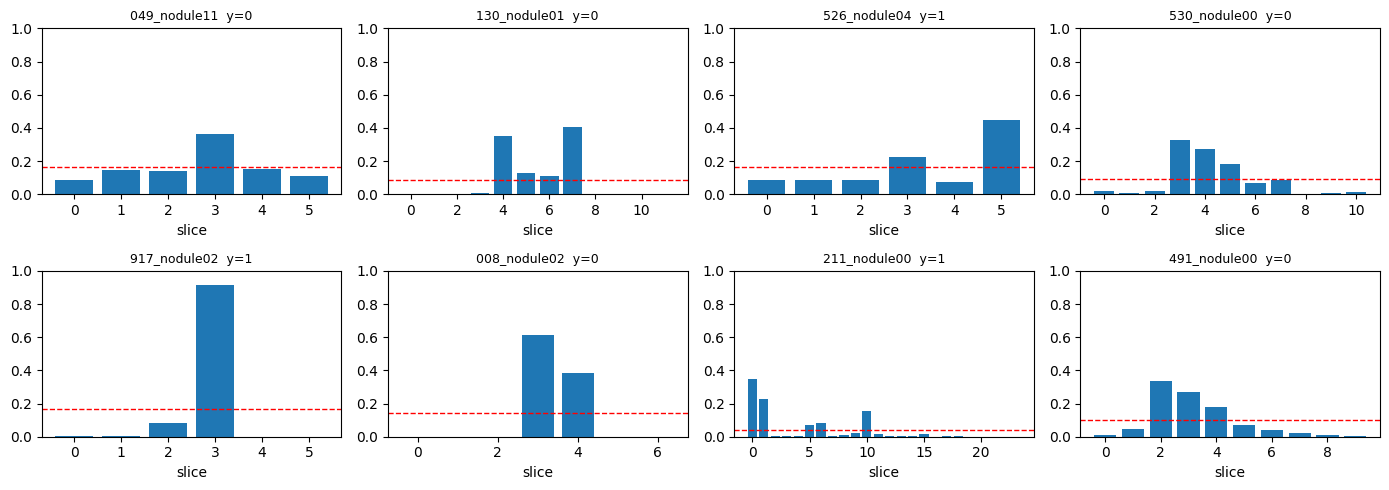

mean normalised attention entropy: 0.601


In [34]:
ids_show = df.sample(min(8, len(df)), random_state=1)["nodule_id"].tolist()
fig, axs = plt.subplots(2, 4, figsize=(14, 5))
for ax, nid in zip(axs.ravel(), ids_show):
    a = attn_store[nid]; ax.bar(range(len(a)), a); ax.axhline(1 / len(a), color="r", ls="--", lw=1)
    ax.set_title(f"{nid[-12:]}  y={int(df.loc[df.nodule_id == nid, 'y'].iloc[0])}", fontsize=9); ax.set_xlabel("slice"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

# how concentrated is the attention? normalised entropy: 1 = uniform, 0 = single slice
ent = [(-(a * np.log(a + 1e-12)).sum() / np.log(len(a))) for a in attn_store.values() if len(a) > 1]
print(f"mean normalised attention entropy: {np.mean(ent):.3f}")

Let's fit the attention-pooled bag vectors and feed those to an SVM, which was the machine learning model with the best performance in prediction.

In [35]:
@torch.no_grad()
def extract_bag_embeddings(model, loader):
    """Returns (embeddings [N, PROJ_DIM], labels [N], ids)."""
    model.eval()
    E, Y, I = [], [], []
    for X, M, y, ids in loader:
        X, M = X.to(DEVICE), M.to(DEVICE)
        h = model.proj(X)
        e = model.w(torch.tanh(model.V(h)) * torch.sigmoid(model.U(h))).squeeze(-1)
        e = e.masked_fill(~M, float("-inf"))
        a = torch.softmax(e, dim=1)
        v = torch.bmm(a.unsqueeze(1), h).squeeze(1)      # (B, PROJ_DIM)
        E.append(v.cpu()); Y.append(y); I += ids
    return torch.cat(E).numpy(), torch.cat(Y).numpy(), I

In [36]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def load_attention_model(fold):
    ckpt = torch.load(CHECKPOINT_DIR / f"mil_attention_fold_{fold}.pt", map_location=DEVICE)
    m = MILNet(**ckpt["model_config"]).to(DEVICE)
    m.load_state_dict(ckpt["model_state_dict"])
    return m

def loader_for(frame):
    return DataLoader(NoduleBags(frame), batch_size=BATCH_SIZE, collate_fn=collate)

svm_results, svm_oof = [], np.zeros((len(df), N_CLASSES))
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

for fold, (tr_idx, te_idx) in enumerate(sgkf.split(df, df["y"], df["patient_id"])):
    model = load_attention_model(fold)
    train_df, test_df = df.iloc[tr_idx], df.iloc[te_idx]

    Xtr, ytr, ids_tr = extract_bag_embeddings(model, loader_for(train_df))
    Xte, yte, ids_te = extract_bag_embeddings(model, loader_for(test_df))
    assert ids_tr == train_df["nodule_id"].tolist() and ids_te == test_df["nodule_id"].tolist()

    svm = make_pipeline(
        StandardScaler(),
        PCA(n_components=0.95, svd_solver='full', random_state=SEED),
        SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", probability=True, random_state=SEED),
    )
    svm.fit(Xtr, ytr)
    prob = svm.predict_proba(Xte)
    svm_oof[te_idx] = prob

    svm_results.append(dict(fold=fold, **metrics(yte, prob)))   # your existing metrics() handles multiclass

res_svm = pd.DataFrame(svm_results)
print(res_svm.round(3))
print(res_svm[["auc", "acc", "f1"]].agg(["mean", "std"]).round(3))
print("pooled OOF:", {k: round(v, 3) for k, v in metrics(df["y"].values, svm_oof).items()})

   fold    auc    acc     f1
0     0  0.726  0.700  0.791
1     1  0.658  0.667  0.758
2     2  0.698  0.651  0.737
3     3  0.687  0.693  0.780
4     4  0.723  0.677  0.758
        auc    acc     f1
mean  0.698  0.677  0.765
std   0.028  0.020  0.021
pooled OOF: {'auc': 0.691, 'acc': 0.677, 'f1': 0.765}


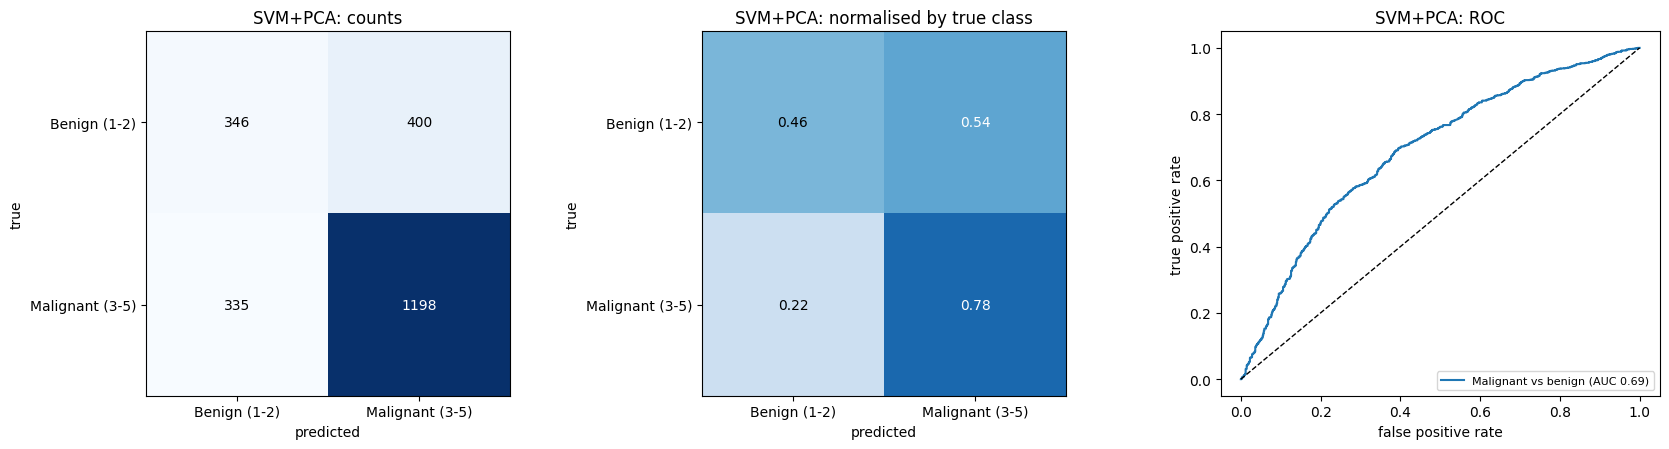

In [37]:
from sklearn.metrics import roc_curve, auc as sk_auc, classification_report

y_all = df["y"].values
pred_svm = svm_oof.argmax(1)
class_names = ["Benign (1-2)", "Malignant (3-5)"]

fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))

# 1) confusion matrix, counts (same style as the MIL cell)
cm = confusion_matrix(y_all, pred_svm)
axs[0].imshow(cm, cmap="Blues"); axs[0].set_title("SVM+PCA: counts")
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        axs[0].text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")

# 2) confusion matrix, row-normalised (per-class recall on the diagonal)
cmn = confusion_matrix(y_all, pred_svm, normalize="true")
axs[1].imshow(cmn, cmap="Blues", vmin=0, vmax=1); axs[1].set_title("SVM+PCA: normalised by true class")
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        axs[1].text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center",
                    color="white" if cmn[i, j] > 0.5 else "black")

for ax in axs[:2]:
    ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
    ax.set_xticklabels(class_names); ax.set_yticklabels(class_names)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")

# 3) binary ROC curve using malignant-class probabilities
fpr, tpr, _ = roc_curve(y_all, svm_oof[:, 1])
axs[2].plot(fpr, tpr, label=f"Malignant vs benign (AUC {sk_auc(fpr, tpr):.2f})")
axs[2].plot([0, 1], [0, 1], "k--", lw=1)
axs[2].set_xlabel("false positive rate"); axs[2].set_ylabel("true positive rate")
axs[2].set_title("SVM+PCA: ROC"); axs[2].legend(fontsize=8, loc="lower right")

plt.tight_layout(); plt.show()

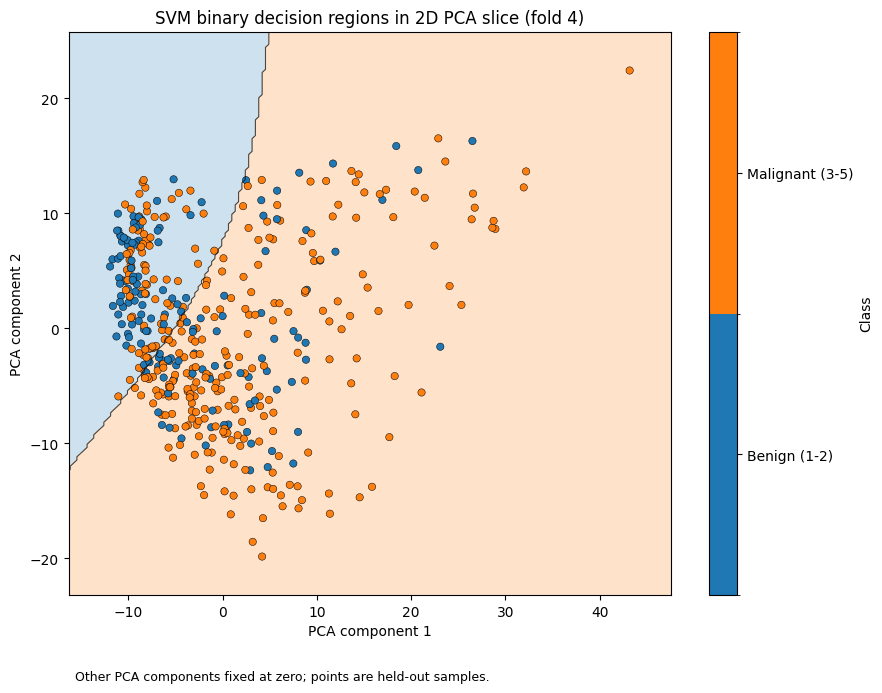

In [38]:
from matplotlib.colors import BoundaryNorm, ListedColormap

scaler = svm.named_steps["standardscaler"]
pca = svm.named_steps["pca"]
svc = svm.named_steps["svc"]

# Show a 2D slice of the fitted high-dimensional SVM boundary.
Xte_pca = pca.transform(scaler.transform(Xte))
margin = 0.08
x_min, x_max = Xte_pca[:, 0].min(), Xte_pca[:, 0].max()
y_min, y_max = Xte_pca[:, 1].min(), Xte_pca[:, 1].max()
x_pad = (x_max - x_min) * margin
y_pad = (y_max - y_min) * margin
xx, yy = np.meshgrid(
    np.linspace(x_min - x_pad, x_max + x_pad, 180),
    np.linspace(y_min - y_pad, y_max + y_pad, 180),
)
grid_pca = np.zeros((xx.size, pca.n_components_))
grid_pca[:, 0] = xx.ravel()
grid_pca[:, 1] = yy.ravel()
regions = svc.predict(grid_pca).reshape(xx.shape)

colors = plt.get_cmap("tab10").colors[:N_CLASSES]
class_cmap = ListedColormap(colors)
class_norm = BoundaryNorm(np.arange(-0.5, N_CLASSES + 0.5), N_CLASSES)
fig, ax = plt.subplots(figsize=(9, 7))
ax.contourf(xx, yy, regions, levels=np.arange(-0.5, N_CLASSES + 0.5),
            cmap=class_cmap, norm=class_norm, alpha=0.22)
ax.contour(xx, yy, regions, levels=np.arange(N_CLASSES - 1) + 0.5,
           colors="black", linewidths=0.8, alpha=0.65)
points = ax.scatter(Xte_pca[:, 0], Xte_pca[:, 1], c=yte, cmap=class_cmap,
                    norm=class_norm, edgecolors="black", linewidths=0.35, s=28)
colorbar = fig.colorbar(points, ax=ax, ticks=np.arange(N_CLASSES))
colorbar.ax.set_yticklabels(class_names)
colorbar.set_label("Class")
ax.set_xlabel("PCA component 1")
ax.set_ylabel("PCA component 2")
ax.set_title(f"SVM binary decision regions in 2D PCA slice (fold {fold})")
ax.text(0.01, -0.15,
        "Other PCA components fixed at zero; points are held-out samples.",
        transform=ax.transAxes, fontsize=9)
plt.tight_layout()
plt.show()